In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import plotly.graph_objects as go

xmin, xmax = -5, 5
ymin, ymax = -5, 5
zmin, zmax = -5, 5
x0, y0, z0 = -1, 2, 1
a, b, c = 0.5, 1, 1.5

def in1(P):
    ins = P[:, 2] >= 3 - P[:, 1] - P[:, 0]
    return ins

def in2(P):
    ins = (P[:, 2] <= 1 - 0.2*P[:, 1] - 0.2*P[:, 0]) & (P[:, 2] >= -1 - 0.2*P[:, 1] - 0.2*P[:, 0])
    return ins

def in3(P):
    ins = (P[:, 0] >= x0 - a) & (P[:, 0] <= x0 + a) & (P[:, 1] >= y0 - b) & (P[:, 1] <= y0 + b) & (P[:, 2] >= z0 - c) & (P[:, 2] <= z0 + c)
    return ins

def ran_mod(n, mod):
    points = []
    i = 0
    while i < n:
        z1 = np.random.uniform(low=xmin, high=xmax, size=n)
        z2 = np.random.uniform(low=ymin, high=ymax, size=n)
        z3 = np.random.uniform(low=zmin, high=zmax, size=n)
        P = np.column_stack((z1, z2, z3))
        if mod == 1:
                P = P[in1(P)] #выберем все все квадратиков 
                points.append(P)
                i += len(P)
                return np.vstack(points)[:n] #np.vstack(points) склеивает все порции из списка друг под другом в одну большую таблицу. [:n] — это срез, «взять строки с начала до n». Последняя порция могла дать лишние точки, и мы обрезаем результат ровно до n
        if mod == 2:        
            P = P[in2(P)] #выберем все все квадратиков 
            points.append(P)
            i += len(P)
            return np.vstack(points)[:n] #np.vstack(points) склеивает все порции из списка друг под другом в одну большую таблицу. [:n] — это срез, «взять строки с начала до n». Последняя порция могла дать лишние точки, и мы обрезаем результат ровно до n
        if mod == 3:        
                    P = P[~in3(P)] #выберем все все квадратиков 
                    points.append(P)
                    i += len(P)
                    return np.vstack(points)[:n] #np.vstack(points) склеивает все порции из списка друг под другом в одну большую таблицу. [:n] — это срез, «взять строки с начала до n». Последняя порция могла дать лишние точки, и мы обрезаем результат ровно до n
           


In [12]:
prec = 300

t1 = ran_mod(prec, 1)
t2 = ran_mod(prec, 2)
t3 = ran_mod(prec, 3)

import plotly.graph_objects as go

samples = [t1, t2, t3]
names   = ['выборка 1', 'выборка 2', 'выборка 3']
colors  = ['red', 'blue', 'green']

fig = go.Figure()

# ---------- точки выборок ----------
for t, name, color in zip([t1, t2, t3],
                          ['класс 1', 'класс 2', 'класс 3'],
                          ['red', 'blue', 'green']):
    fig.add_trace(go.Scatter3d(x=t[:, 0], y=t[:, 1], z=t[:, 2], mode='markers',
                               marker=dict(size=3, color=color, opacity=0.8), name=name))

# ---------- плоскости ----------
gx, gy = np.meshgrid(np.linspace(xmin, xmax, 40), np.linspace(ymin, ymax, 40))

def add_plane(gz, color, name):
    gz = gz.copy()
    gz[(gz < zmin) | (gz > zmax)] = np.nan          # обрезаем по границам куба
    fig.add_trace(go.Surface(x=gx, y=gy, z=gz, opacity=0.35,
                             colorscale=[[0, color], [1, color]], showscale=False,
                             name=name, showlegend=True))

add_plane(3 - gx - gy,               'red',  'x + y + z = 3')
add_plane(1 - 0.2 * gx - 0.2 * gy,   'blue', 'z = 1 − 0.2x − 0.2y')
add_plane(-1 - 0.2 * gx - 0.2 * gy,  'blue', 'z = −1 − 0.2x − 0.2y')

# ---------- параллелепипед ----------
bx = [x0 - a, x0 + a]
by = [y0 - b, y0 + b]
bz = [z0 - c, z0 + c]

# 8 вершин
vx, vy, vz = np.array([[x, y, z] for x in bx for y in by for z in bz]).T

# полупрозрачные грани
fig.add_trace(go.Mesh3d(x=vx, y=vy, z=vz, alphahull=0, opacity=0.25,
                        color='green', name='параллелепипед', showlegend=True))

# рёбра (12 линий)
edges = [(0,1),(2,3),(4,5),(6,7),   # вдоль z
         (0,2),(1,3),(4,6),(5,7),   # вдоль y
         (0,4),(1,5),(2,6),(3,7)]   # вдоль x
ex, ey, ez = [], [], []
for i, j in edges:
    ex += [vx[i], vx[j], None]      # None — разрыв между отрезками
    ey += [vy[i], vy[j], None]
    ez += [vz[i], vz[j], None]
fig.add_trace(go.Scatter3d(x=ex, y=ey, z=ez, mode='lines',
                           line=dict(color='darkgreen', width=4), showlegend=False))

# ---------- оформление ----------
fig.update_layout(
    scene=dict(xaxis=dict(title='x', range=[xmin, xmax]),
               yaxis=dict(title='y', range=[ymin, ymax]),
               zaxis=dict(title='z', range=[zmin, zmax]),
               aspectmode='cube'),          # одинаковый масштаб по осям
    width=900, height=800,
    legend=dict(itemsizing='constant')
)
fig.show()

In [38]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

lab1 = np.zeros(len(t1))
lab2 = np.ones(len(t2))
lab3 = np.ones(len(t3))

Xt = np.vstack([t1, t2, t3])
Yt = np.concatenate([lab1, lab2, lab3])

x_tr, xt, y_tr, yt = train_test_split(Xt, Yt, test_size=0.2, random_state=9) #парметр random_state определяет способ выбора 20 и 80 процентов из выборки. Генератор случайных числев будет стартовать с всегда с 9
scaler = StandardScaler()
x_tr_sc = scaler.fit_transform(x_tr)
xt_sc = scaler.transform(xt)


In [36]:
from sklearn.neural_network import MLPClassifier

mlp = MLPClassifier(
    hidden_layer_sizes=(1,9), 
    activation='relu', #tanh, relu
    solver='lbfgs', #стохастический градиентный спуск, который сам себе параметры подбирает, умнее адама тк квазиньютоновский метод использует не только наклон, но и приближённую кривизну поверхности ошибки, поэтому выбирает шаги «умнее».
    learning_rate_init=0.015,
    max_iter=2000, #максимум эпох (проходов по всей обучающей выборке)
    random_state=9
)

(6, 9): 0.880 с
(11, 9): 0.238 с
(16, 9): 2.045 с
(21, 9): 0.578 с
(26, 9): 0.624 с
(31, 9): 0.374 с
(36, 9): 0.195 с
(41, 9): 0.157 с
(46, 9): 0.311 с
(51, 9): 0.734 с


,нейронов в 1-м слое,архитектура,"время, с",время std,эпох,precision обуч.,recall обуч.,precision тест,recall тест
0,6,"(6, 9)",0.880,0.009,923,0.929,0.965,0.822,0.870
1,11,"(11, 9)",0.238,0.011,208,0.854,0.989,0.835,0.957
2,16,"(16, 9)",2.045,0.007,2000,0.975,0.975,0.822,0.870
3,21,"(21, 9)",0.578,0.007,588,0.986,0.986,0.861,0.899
4,26,"(26, 9)",0.624,0.001,598,0.982,0.979,0.868,0.855
5,31,"(31, 9)",0.374,0.004,319,0.993,0.937,0.862,0.812
6,36,"(36, 9)",0.195,0.002,138,0.863,0.996,0.815,0.957
7,41,"(41, 9)",0.157,0.002,112,0.932,0.972,0.836,0.884
8,46,"(46, 9)",0.311,0.003,208,0.863,0.996,0.815,0.957
9,51,"(51, 9)",0.734,0.004,574,1.000,1.000,0.838,0.826


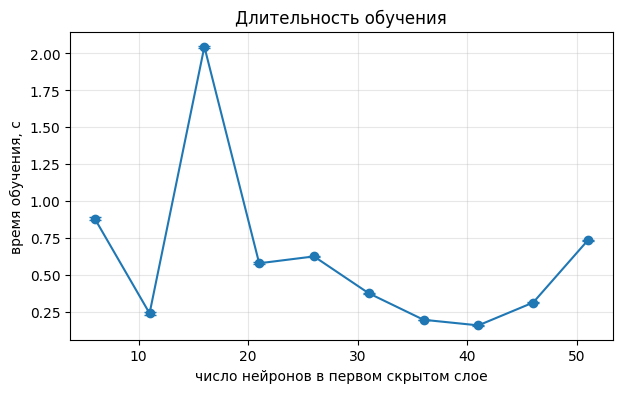

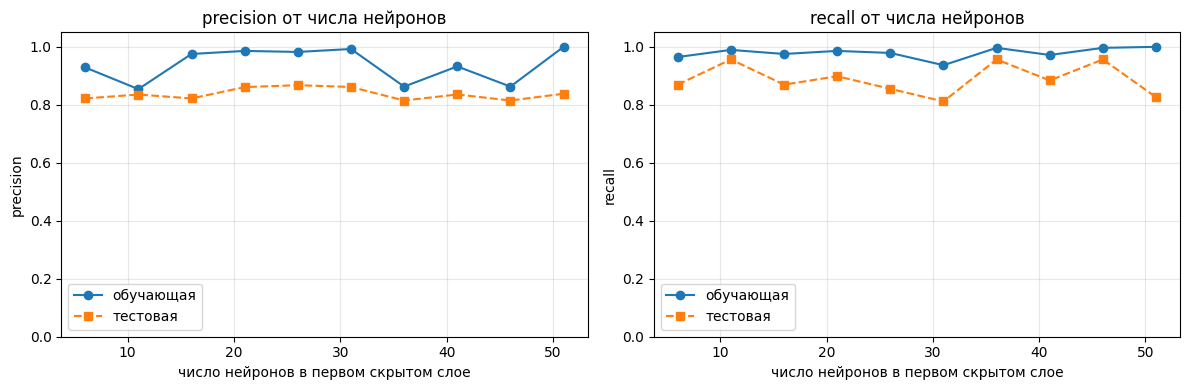

In [40]:
import time
import warnings
import pandas as pd
from sklearn.base import clone
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import precision_score, recall_score

warnings.filterwarnings('ignore', category=ConvergenceWarning)   # чтобы не засоряли вывод

POS = 1            # метка класса, для которого считаем precision/recall (у тебя 1 — это «слой»)
n_nets = 10        # сколько сетей
step = 5           # на сколько увеличиваем первый слой
n_repeats = 3      # сколько раз обучаем каждую сеть (для усреднения времени)

base_layers = mlp.hidden_layer_sizes                 # архитектура исходной сети, например (16, 8)
if isinstance(base_layers, int):                     # если записано (16,) как число
    base_layers = (base_layers,)
first = base_layers[0]
rest = tuple(base_layers[1:])                        # остальные слои не меняем

rows = []
for i in range(1, n_nets + 1):
    n1 = first + step * i                            # нейронов в первом слое
    layers = (n1,) + rest

    times = []
    for r in range(n_repeats):
        net = clone(mlp).set_params(hidden_layer_sizes=layers)   # те же настройки, другой размер
        t0 = time.perf_counter()                     # засекаем время
        net.fit(x_tr_sc, y_tr)
        times.append(time.perf_counter() - t0)       # сколько секунд длилось обучение

    # метрики считаем по последней обученной сети
    pred_tr = net.predict(x_tr_sc)
    pred_te = net.predict(xt_sc)
    rows.append({
        'нейронов в 1-м слое': n1,
        'архитектура': layers,
        'время, с': np.mean(times),
        'время std': np.std(times),
        'эпох': net.n_iter_,
        'precision обуч.': precision_score(y_tr, pred_tr, pos_label=POS, zero_division=0),
        'recall обуч.':    recall_score(y_tr, pred_tr, pos_label=POS, zero_division=0),
        'precision тест':  precision_score(yt, pred_te, pos_label=POS, zero_division=0),
        'recall тест':     recall_score(yt, pred_te, pos_label=POS, zero_division=0),
    })
    print(f"{layers}: {np.mean(times):.3f} с")

res = pd.DataFrame(rows)
display(res.round(3))

n = res['нейронов в 1-м слое']

# 1. Время обучения
plt.figure(figsize=(7, 4))
plt.errorbar(n, res['время, с'], yerr=res['время std'], marker='o', capsize=4)
plt.xlabel('число нейронов в первом скрытом слое')
plt.ylabel('время обучения, с')
plt.title('Длительность обучения')
plt.grid(alpha=0.3)
plt.show()

# 2. Precision и recall
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for k, metric in enumerate(['precision', 'recall']):
    ax[k].plot(n, res[f'{metric} обуч.'], 'o-', label='обучающая')
    ax[k].plot(n, res[f'{metric} тест'],  's--', label='тестовая')
    ax[k].set_xlabel('число нейронов в первом скрытом слое')
    ax[k].set_ylabel(metric)
    ax[k].set_title(f'{metric} от числа нейронов')
    ax[k].set_ylim(0, 1.05)
    ax[k].grid(alpha=0.3); ax[k].legend()
plt.tight_layout()
plt.show()

In [ ]:
# ---------- метрики ----------
mlp = mlp.set_params(hidden_layer_sizes=(11, 9))
mlp.fit(x_tr_sc, y_tr)
y_pr = mlp.predict(xt_sc)
prec = precision_score(yt, y_pr)
rec = recall_score(yt, y_pr)

fig = go.Figure()

# ---------- 1. «заливка»: граница области, которую сеть считает классом 1 ----------
res = 35
gx, gy, gz = np.meshgrid(np.linspace(xmin, xmax, res),
                         np.linspace(ymin, ymax, res),
                         np.linspace(zmin, zmax, res), indexing='ij')
grid = np.column_stack((gx.ravel(), gy.ravel(), gz.ravel()))
p = mlp.predict_proba(scaler.transform(grid))[:, 1]     # вероятность класса 1

fig.add_trace(go.Isosurface(
    x=gx.ravel(), y=gy.ravel(), z=gz.ravel(), value=p,
    isomin=0.5, isomax=0.5, surface_count=1,
    opacity=0.25, colorscale=[[0, 'lightblue'], [1, 'lightblue']], showscale=False,
    caps=dict(x_show=False, y_show=False, z_show=False),
    name='граница сети', showlegend=True))

# ---------- 2. тестовые точки, цвет — правильная метка ----------
for lab, color in [(0, 'red'), (1, 'blue')]:
    m = (yt == lab)
    fig.add_trace(go.Scatter3d(x=xt[m, 0], y=xt[m, 1], z=xt[m, 2], mode='markers',
                               marker=dict(size=3, color=color), name=f'класс {lab}'))

# ---------- 3. настоящие границы: плоскости ----------
px, py = np.meshgrid(np.linspace(xmin, xmax, 20), np.linspace(ymin, ymax, 20))

def add_plane(pz, name):
    pz = pz.copy()
    pz[(pz < zmin) | (pz > zmax)] = np.nan
    fig.add_trace(go.Surface(x=px, y=py, z=pz, opacity=0.15,
                             colorscale=[[0, 'black'], [1, 'black']], showscale=False,
                             name=name, showlegend=True))

add_plane(3 - px - py,             'x + y + z = 3')
add_plane(1 - 0.2 * px - 0.2 * py,  'верх слоя')
add_plane(-1 - 0.2 * px - 0.2 * py, 'низ слоя')

# ---------- 4. настоящий параллелепипед (рёбра, как рамки квадратов в 2D) ----------
verts = np.array([[x, y, z] for x in [x0 - a, x0 + a]
                            for y in [y0 - b, y0 + b]
                            for z in [z0 - c, z0 + c]])
edges = [(0,1),(2,3),(4,5),(6,7),(0,2),(1,3),(4,6),(5,7),(0,4),(1,5),(2,6),(3,7)]
ex, ey, ez = [], [], []
for i, j in edges:
    ex += [verts[i, 0], verts[j, 0], None]
    ey += [verts[i, 1], verts[j, 1], None]
    ez += [verts[i, 2], verts[j, 2], None]
fig.add_trace(go.Scatter3d(x=ex, y=ey, z=ez, mode='lines',
                           line=dict(color='black', width=4), name='параллелепипед'))

# ---------- оформление ----------
fig.update_layout(
    title=f'precision = {prec:.3f}, recall = {rec:.3f}',
    scene=dict(xaxis=dict(title='x', range=[xmin, xmax]),
               yaxis=dict(title='y', range=[ymin, ymax]),
               zaxis=dict(title='z', range=[zmin, zmax]),
               aspectmode='cube'),
    width=900, height=800, legend=dict(itemsizing='constant'))
fig.show()

print(prec, rec)
# граница сети -- места, где вероятность класса 1 равна 0.5. Внутри неё сеть отвечает «класс 1», снаружи — «класс 0».

0.8354430379746836 0.9565217391304348
